In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
%pip install -q statsmodels
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

SEED = 42

# Resolve the existing project layout without moving any folders.
# This notebook is inside the inner project/notebooks folder, while the
# processed CSVs shown in the user's Explorer are in the outer data folder.
_CWD = Path.cwd().resolve()
_PROCESSED_CANDIDATES = [
    _CWD / "data" / "processed",
    _CWD.parent / "data" / "processed",
    _CWD.parent.parent / "data" / "processed",
]
PROCESSED = next(
    (p for p in _PROCESSED_CANDIDATES if
     (p / "country_total.csv").exists() or
     (p / "household_country_total.csv").exists() or
     (p / "households_country_total.csv").exists()),
    _PROCESSED_CANDIDATES[0],
)

# Keep generated artifacts beside app.py in the inner project folder.
_PROJECT_ROOT = next(
    (p for p in [_CWD, _CWD.parent] if (p / "app.py").exists()),
    _CWD.parent,
)
OUTPUTS = _PROJECT_ROOT / "outputs"
FIG_DIR = OUTPUTS / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = OUTPUTS / "evaluation_reports"; TAB_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR = OUTPUTS / "predictions"; PRED_DIR.mkdir(parents=True, exist_ok=True)

_COUNTRY_TOTAL_CANDIDATES = [
    PROCESSED / "country_total.csv",
    PROCESSED / "household_country_total.csv",
    PROCESSED / "households_country_total.csv",
]
_COUNTRY_TOTAL_PATH = next((p for p in _COUNTRY_TOTAL_CANDIDATES if p.exists()), None)
if _COUNTRY_TOTAL_PATH is None:
    raise FileNotFoundError(
        "Country totals CSV not found. Looked for: " +
        ", ".join(str(p) for p in _COUNTRY_TOTAL_CANDIDATES)
    )

country_total = pd.read_csv(_COUNTRY_TOTAL_PATH)
_REQUIRED_COLUMNS = {"country", "year", "energy_tj"}
_MISSING_COLUMNS = _REQUIRED_COLUMNS - set(country_total.columns)
if _MISSING_COLUMNS:
    raise ValueError(
        f"{_COUNTRY_TOTAL_PATH.name} is missing required columns: "
        f"{sorted(_MISSING_COLUMNS)}. Available columns: {country_total.columns.tolist()}"
    )
country_total = country_total.sort_values(["country", "year"]).reset_index(drop=True)

print(f"Historical totals loaded from: {_COUNTRY_TOTAL_PATH}")
print(f"Forecast artifacts will be saved under: {PRED_DIR}")

sns.set_theme(style="whitegrid", context="notebook")

pd.DataFrame({
    "rows": [len(country_total)],
    "countries": [country_total.country.nunique()],
    "years": [f"{country_total.year.min()}-{country_total.year.max()}"],
    "obs_per_country": [country_total.groupby("country").size().describe()[["min","50%","max"]].to_dict()],
})

Note: you may need to restart the kernel to use updated packages.
Historical totals loaded from: C:\Users\LOQ\Downloads\European_Household_Energy_Project\data\processed\country_total.csv
Forecast artifacts will be saved under: C:\Users\LOQ\Downloads\European_Household_Energy_Project\European_Household_Energy_Project\outputs\predictions


,rows,countries,years,obs_per_country
0,386,30,2010-2024,"{'min': 10.0, '50%': 15.0, 'max': 15.0}"


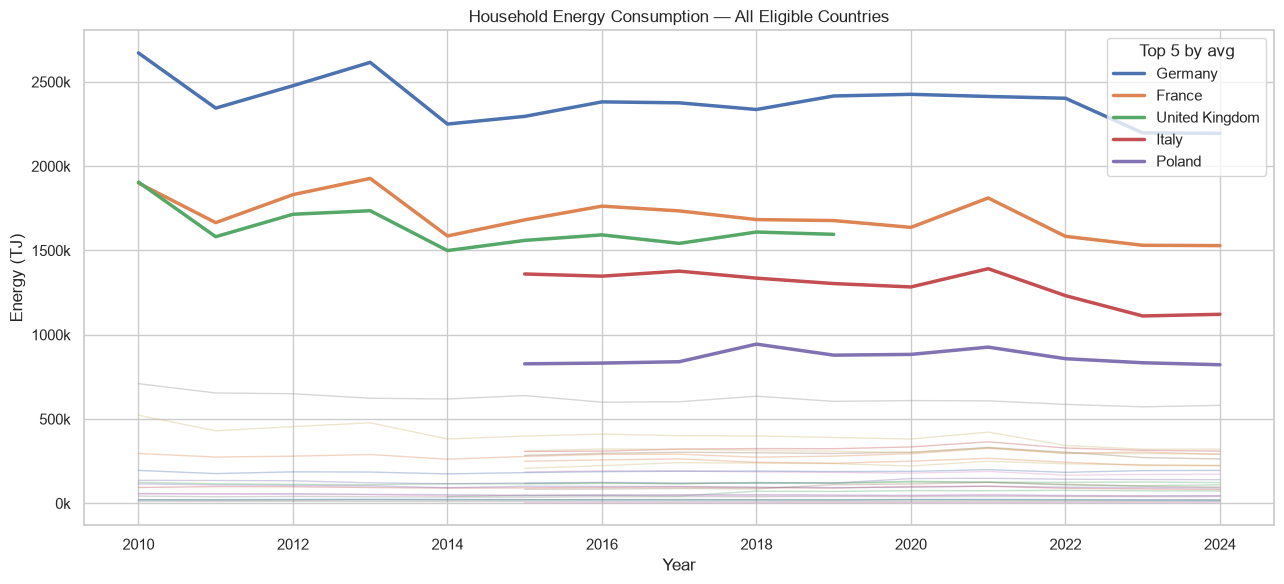

In [2]:
fig, ax = plt.subplots(figsize=(13, 6))
for country in country_total.country.unique():
    series = country_total[country_total.country == country]
    ax.plot(series.year, series.energy_tj, alpha=0.35, linewidth=1)

# Highlight top 5 by average
top5 = (country_total.groupby("country").energy_tj.mean()
        .sort_values(ascending=False).head(5).index.tolist())
for country in top5:
    series = country_total[country_total.country == country]
    ax.plot(series.year, series.energy_tj, linewidth=2.5, label=country)

ax.set_title("Household Energy Consumption — All Eligible Countries")
ax.set_xlabel("Year"); ax.set_ylabel("Energy (TJ)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
ax.legend(loc="upper right", title="Top 5 by avg")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase4_historical_trends.png", bbox_inches="tight")
plt.show()

In [3]:
def wape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.sum(np.abs(y_true))
    return np.nan if denom == 0 else np.sum(np.abs(y_true - y_pred)) / denom * 100

In [4]:
def forecast_naive(train_y, horizon):
    return np.repeat(train_y[-1], horizon)

def forecast_drift(train_y, horizon):
    if len(train_y) < 2:
        return np.repeat(train_y[-1], horizon)
    drift = (train_y[-1] - train_y[0]) / (len(train_y) - 1)
    return train_y[-1] + drift * np.arange(1, horizon + 1)

def forecast_linear_trend(train_y, horizon):
    if len(train_y) < 2:
        return np.repeat(train_y[-1], horizon)
    x = np.arange(len(train_y))
    coefs = np.polyfit(x, train_y, 1)
    x_future = np.arange(len(train_y), len(train_y) + horizon)
    return np.polyval(coefs, x_future)

"Baselines ready ✅"

'Baselines ready ✅'

In [5]:
def forecast_ses(train_y, horizon):
    if len(train_y) < 2:
        return np.repeat(train_y[-1], horizon)
    try:
        model = SimpleExpSmoothing(train_y, initialization_method="estimated").fit(optimized=True)
        return model.forecast(horizon)
    except Exception:
        return np.repeat(train_y[-1], horizon)

def forecast_holt(train_y, horizon):
    if len(train_y) < 3:
        return np.repeat(train_y[-1], horizon)
    try:
        model = ExponentialSmoothing(train_y, trend="add", initialization_method="estimated").fit(optimized=True)
        return model.forecast(horizon)
    except Exception:
        return np.repeat(train_y[-1], horizon)

def forecast_arima(train_y, horizon):
    if len(train_y) < 8:
        return np.repeat(train_y[-1], horizon)
    try:
        model = ARIMA(train_y, order=(1, 1, 1)).fit()
        return model.forecast(horizon)
    except Exception:
        return np.repeat(train_y[-1], horizon)

"Advanced models ready ✅"

'Advanced models ready ✅'

In [6]:
MODELS = {
    "Naive":  forecast_naive,
    "Drift":  forecast_drift,
    "Linear": forecast_linear_trend,
    "SES":    forecast_ses,
    "Holt":   forecast_holt,
    "ARIMA":  forecast_arima,
}
N_ORIGINS = 3   # last 3 years of each series used as test origins
HORIZON   = 1   # 1-step-ahead backtest

backtest_rows = []

for country in country_total.country.unique():
    series_df = country_total[country_total.country == country].sort_values("year")
    y = series_df.energy_tj.values
    years = series_df.year.values
    n = len(y)
    if n < N_ORIGINS + 5:
        continue

    for origin_idx in range(n - N_ORIGINS, n):
        train_y = y[:origin_idx]
        actual = y[origin_idx]
        test_year = years[origin_idx]
        for name, fn in MODELS.items():
            try:
                pred = fn(train_y, HORIZON)[0]
                pred = max(pred, 0)  # clip negative
            except Exception:
                pred = np.nan
            backtest_rows.append({
                "country": country, "year": test_year,
                "model": name, "actual": actual, "pred": pred,
            })

backtest = pd.DataFrame(backtest_rows)
pd.DataFrame({
    "rows": [len(backtest)],
    "countries": [backtest.country.nunique()],
    "models": [backtest.model.nunique()],
    "missing_preds": [int(backtest.pred.isna().sum())],
})

c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.s

,rows,countries,models,missing_preds
0,540,30,6,0


In [7]:
backtest_clean = backtest.dropna(subset=["pred"])

per_model = (
    backtest_clean.groupby("model")
    .apply(lambda df: pd.Series({
        "WAPE_%": wape(df.actual, df.pred),
        "MAE": np.mean(np.abs(df.actual - df.pred)),
        "RMSE": np.sqrt(np.mean((df.actual - df.pred) ** 2)),
        "n_obs": len(df),
    }))
    .sort_values("WAPE_%")
    .round(2)
)

per_model.style.background_gradient(subset=["WAPE_%"], cmap="RdYlGn_r")

,WAPE_%,MAE,RMSE,n_obs
model,,,,
Naive,4.860000,18217.440000,42945.470000,90.000000
Drift,5.180000,19405.930000,42715.210000,90.000000
ARIMA,5.180000,19429.900000,44121.160000,90.000000
Linear,6.290000,23558.180000,42884.270000,90.000000
Holt,6.450000,24172.800000,44209.210000,90.000000
SES,6.670000,25007.270000,54745.000000,90.000000


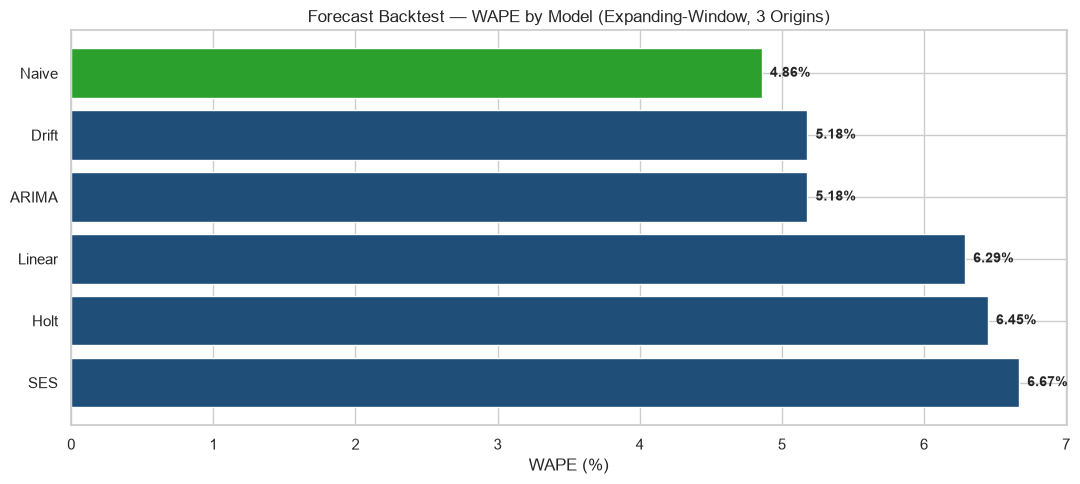

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
order = per_model.index.tolist()
colors = ["#2ca02c" if i == 0 else "#1f4e79" for i in range(len(order))]
ax.barh(order[::-1], per_model["WAPE_%"][::-1], color=colors[::-1])
ax.set_title("Forecast Backtest — WAPE by Model (Expanding-Window, 3 Origins)")
ax.set_xlabel("WAPE (%)")
for i, v in enumerate(per_model["WAPE_%"][::-1]):
    ax.text(v, i, f"  {v:.2f}%", va="center", fontsize=10, fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase4_backtest_wape.png", bbox_inches="tight")
plt.show()

In [9]:
# Each country picks its own best model (min WAPE on its backtest)
def best_model_for_country(df):
    stats = (
        df.groupby("model")
        .apply(lambda d: wape(d.actual, d.pred))
        .to_frame("wape")
        .dropna()
    )
    if stats.empty:
        return pd.Series({"best_model": "Naive", "best_wape": np.nan})
    best = stats.wape.idxmin()
    return pd.Series({"best_model": best, "best_wape": stats.loc[best, "wape"]})

best_per_country = (
    backtest_clean.groupby("country")
    .apply(best_model_for_country)
    .reset_index()
)

best_per_country.sort_values("best_wape").head(10).style.format({"best_wape": "{:.2f}%"})

,country,best_model,best_wape
4,Croatia,Holt,0.91%
27,Spain,Linear,1.02%
22,Portugal,Linear,1.28%
26,Slovenia,Linear,1.35%
8,Finland,SES,1.68%
14,Latvia,Holt,1.76%
24,Serbia,Naive,1.99%
1,Austria,Linear,2.07%
0,Albania,SES,2.08%
7,Estonia,SES,2.23%


In [10]:
FORECAST_YEARS = [2025, 2026, 2027]
forecast_rows = []

for _, row in best_per_country.iterrows():
    country = row.country
    model_name = row.best_model
    series_df = country_total[country_total.country == country].sort_values("year")
    y = series_df.energy_tj.values

    fn = MODELS[model_name]
    preds = fn(y, len(FORECAST_YEARS))

    for yr, pred in zip(FORECAST_YEARS, preds):
        forecast_rows.append({
            "country": country,
            "year": yr,
            "forecast_tj": max(pred, 0),
            "model": model_name,
        })

forecasts = pd.DataFrame(forecast_rows)

# Add last actual value for comparison
last_actual = (
    country_total.sort_values("year").groupby("country").tail(1)
    [["country", "year", "energy_tj"]]
    .rename(columns={"year": "last_year", "energy_tj": "last_actual_tj"})
)
forecasts = forecasts.merge(last_actual, on="country", how="left")
forecasts["change_vs_last_pct"] = (
    (forecasts.forecast_tj - forecasts.last_actual_tj) / forecasts.last_actual_tj * 100
).round(2)

forecasts.head(12).style.format({
    "forecast_tj": "{:,.0f}",
    "last_actual_tj": "{:,.0f}",
    "change_vs_last_pct": "{:+.2f}%",
})

c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_par

,country,year,forecast_tj,model,last_year,last_actual_tj,change_vs_last_pct
0,Albania,2025,"21,656",SES,2024,"20,888",+3.68%
1,Albania,2026,"21,656",SES,2024,"20,888",+3.68%
2,Albania,2027,"21,656",SES,2024,"20,888",+3.68%
3,Austria,2025,"301,663",Linear,2024,"290,076",+3.99%
4,Austria,2026,"303,310",Linear,2024,"290,076",+4.56%
5,Austria,2027,"304,957",Linear,2024,"290,076",+5.13%
6,Bosnia and Herzegovina,2025,"73,246",Naive,2024,"73,246",+0.00%
7,Bosnia and Herzegovina,2026,"73,246",Naive,2024,"73,246",+0.00%
8,Bosnia and Herzegovina,2027,"73,246",Naive,2024,"73,246",+0.00%
9,Bulgaria,2025,"81,905",ARIMA,2024,"82,126",-0.27%


In [11]:
summary = (
    forecasts.groupby("year")
    .agg(
        total_forecast_tj=("forecast_tj", "sum"),
        mean_forecast_tj=("forecast_tj", "mean"),
        countries=("country", "nunique"),
        mean_change_pct=("change_vs_last_pct", "mean"),
    )
    .round(2)
)
summary.style.format({
    "total_forecast_tj": "{:,.0f}",
    "mean_forecast_tj": "{:,.0f}",
    "mean_change_pct": "{:+.2f}%",
}).background_gradient(subset=["mean_change_pct"], cmap="RdYlGn")

,total_forecast_tj,mean_forecast_tj,countries,mean_change_pct
year,,,,
2025,"11,088,804","369,627",30,-0.04%
2026,"11,052,633","368,421",30,-0.27%
2027,"11,015,377","367,179",30,-0.58%


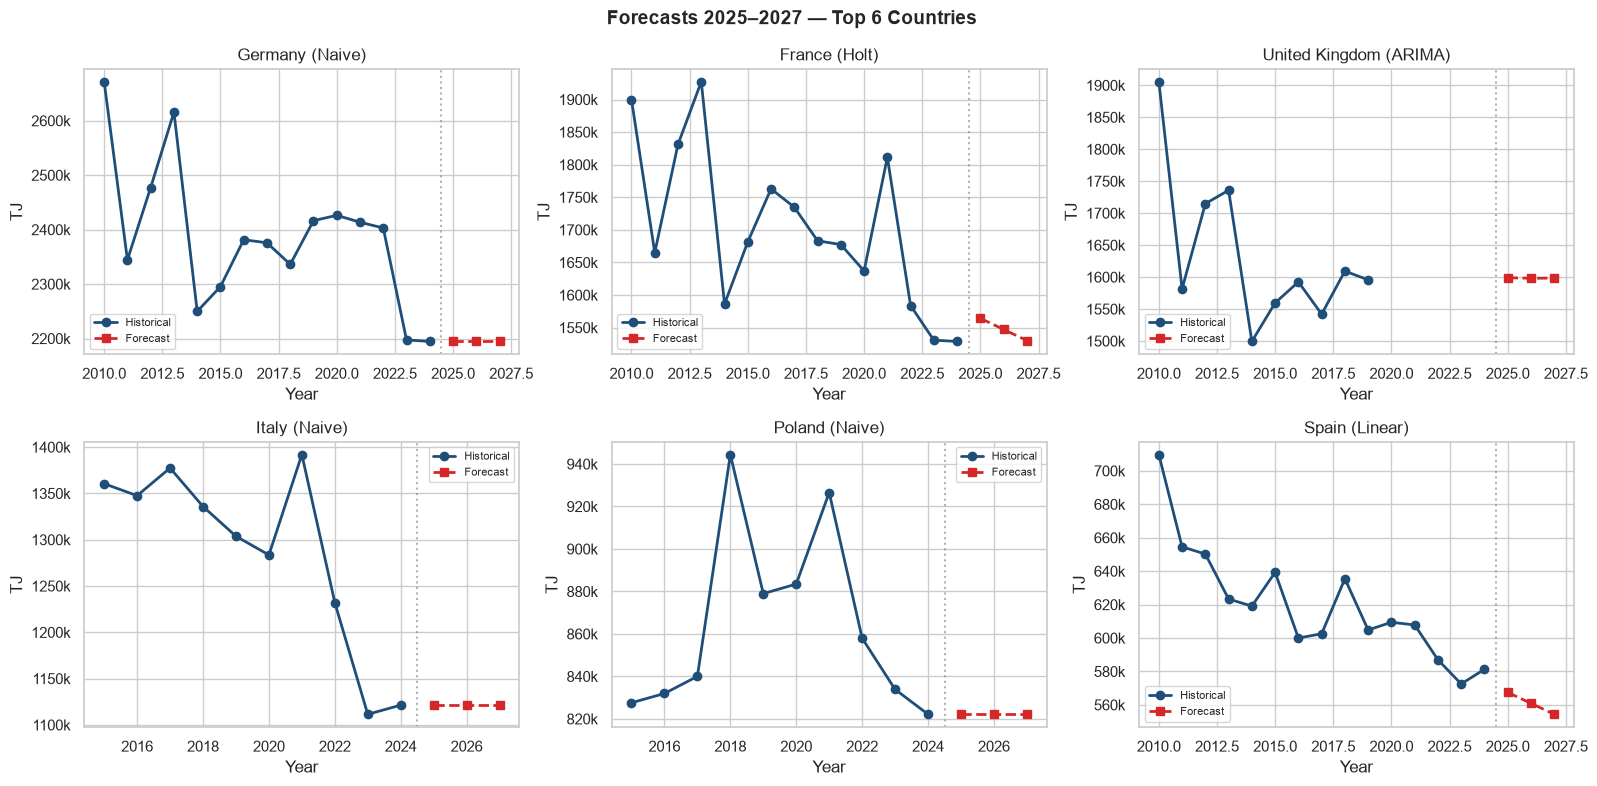

In [12]:
top6 = (country_total.groupby("country").energy_tj.mean()
        .sort_values(ascending=False).head(6).index.tolist())

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, country in enumerate(top6):
    ax = axes[i]
    hist = country_total[country_total.country == country].sort_values("year")
    fc = forecasts[forecasts.country == country].sort_values("year")

    ax.plot(hist.year, hist.energy_tj, marker="o", color="#1f4e79", label="Historical", linewidth=2)
    ax.plot(fc.year, fc.forecast_tj, marker="s", linestyle="--", color="#d62728", label="Forecast", linewidth=2)
    ax.axvline(2024.5, color="grey", linestyle=":", alpha=0.6)
    model_name = fc["model"].iloc[0] if not fc.empty else "No forecast"
    ax.set_title(f"{country} ({model_name})")
    ax.set_xlabel("Year"); ax.set_ylabel("TJ")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
    ax.legend(fontsize=8)

plt.suptitle("Forecasts 2025–2027 — Top 6 Countries", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase4_forecasts_top6.png", bbox_inches="tight")
plt.show()

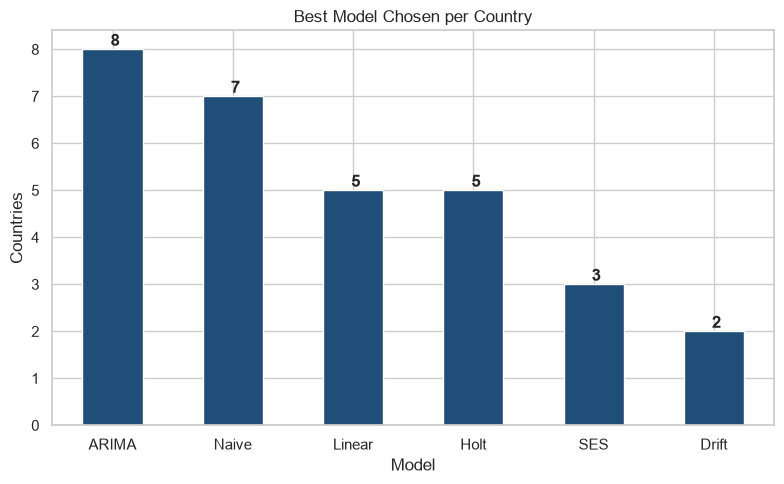

,countries,pct
best_model,,
ARIMA,8,26.70
Naive,7,23.30
Linear,5,16.70
Holt,5,16.70
SES,3,10.00
Drift,2,6.70


In [13]:
model_usage = best_per_country.best_model.value_counts().to_frame("countries")
model_usage["pct"] = (model_usage.countries / model_usage.countries.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 5))
model_usage["countries"].plot(kind="bar", ax=ax, color="#1f4e79")
ax.set_title("Best Model Chosen per Country")
ax.set_xlabel("Model"); ax.set_ylabel("Countries")
plt.xticks(rotation=0)
for i, v in enumerate(model_usage.countries):
    ax.text(i, v, f" {v}", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase4_model_usage.png", bbox_inches="tight")
plt.show()

model_usage

In [14]:
direction = pd.cut(
    forecasts[forecasts.year == 2027].change_vs_last_pct,
    bins=[-np.inf, -10, 0, 10, np.inf],
    labels=["Strong decrease (<-10%)", "Mild decrease (-10–0%)",
            "Mild increase (0–10%)", "Strong increase (>10%)"]
).value_counts().sort_index()

direction.to_frame("countries").style.bar(color="#1f4e79")

,countries
change_vs_last_pct,
Strong decrease (<-10%),0
Mild decrease (-10–0%),23
Mild increase (0–10%),6
Strong increase (>10%),1


In [ ]:
forecasts.to_csv(PRED_DIR / "forecasts_2025_2027.csv", index=False)
best_per_country.to_csv(TAB_DIR / "phase4_best_model_per_country.csv", index=False)
per_model.to_csv(TAB_DIR / "phase4_backtest_results.csv")

pd.DataFrame({
    "file": [
        "forecasts_2025_2027.csv",
        "phase4_best_model_per_country.csv",
        "phase4_backtest_results.csv",
    ],
    "rows": [len(forecasts), len(best_per_country), len(per_model)],
})

,file,rows
0,forecasts_2025_2027.csv,90
1,phase4_best_model_per_country.csv,30
2,phase4_backtest_results.csv,6


: 